# EuroSAT samples after `prepare_eurosat.py`

Shows a few images **from the processed arrays** (`data/eurosat/eurosat_X.npy`): 12 bands (B10 removed), bands in
`config.BANDS` order. Each title says which original folder and file the image came from in `EuroSAT_MS.zip`,
which of the 5 target classes it was merged into, and whether it is in train, validation or test.

The processed array does not store file names. It keeps the order of the zip (sorted by name), so image `i` of the
array is file `i` of the sorted zip listing; the cell below reads only that listing, not the images.

In [1]:
import sys
import zipfile
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT / "src"))

import numpy as np
import matplotlib.pyplot as plt

import config as c

In [2]:
X = np.load(c.EUROSAT_DIR / "eurosat_X.npy", mmap_mode="r")   # (27000, 12, 64, 64) uint16
y = np.load(c.EUROSAT_DIR / "eurosat_y.npy")                  # target class 0-4
y10 = np.load(c.EUROSAT_DIR / "eurosat_y10.npy")              # original class 0-9
split = np.load(c.EUROSAT_DIR / "eurosat_split.npy")          # 0 train, 1 val, 2 test

with zipfile.ZipFile(c.EUROSAT_ZIP) as z:                      # file names only, no image is read
    names = sorted(n for n in z.namelist() if n.endswith(".tif"))

print(X.shape, X.dtype, "| files in zip:", len(names))

(27000, 12, 64, 64) uint16 | files in zip: 27000


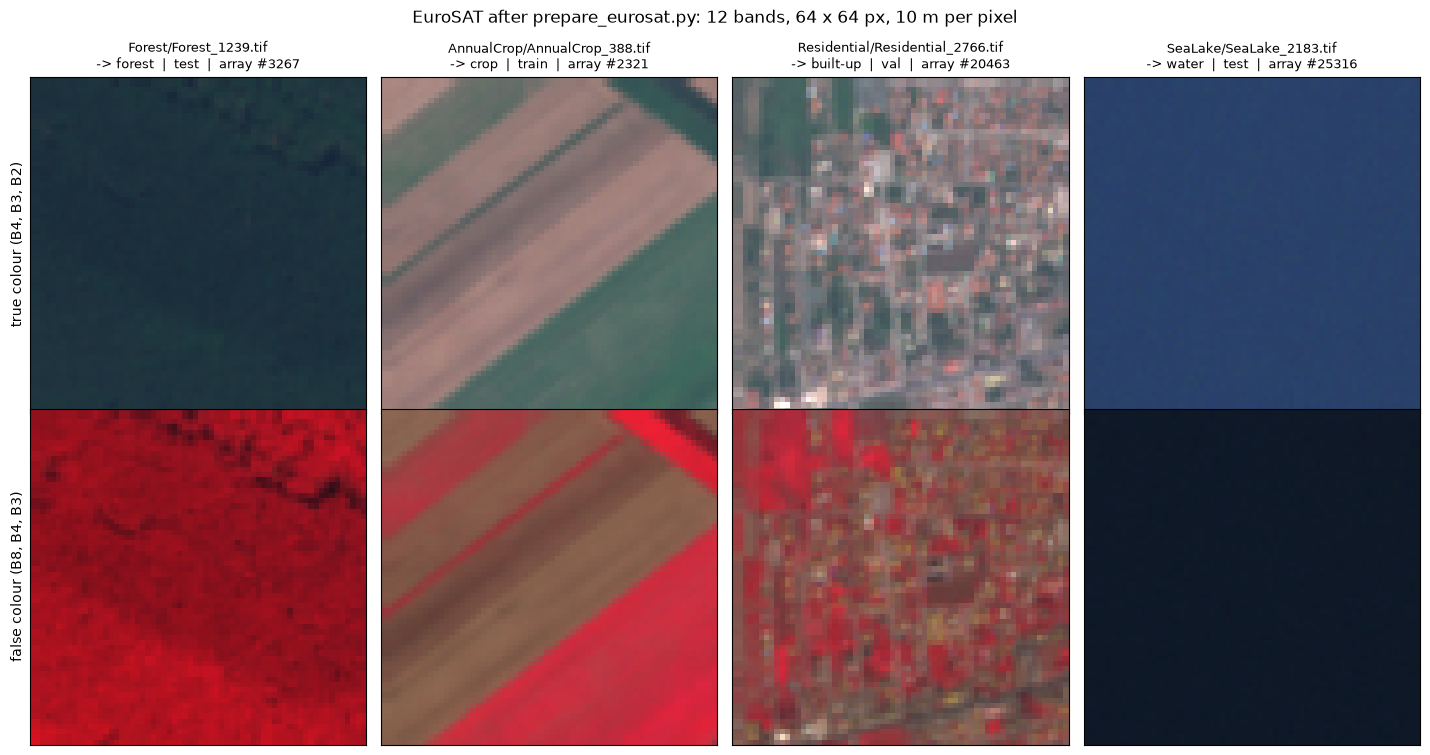

In [3]:
SHOW = ["Forest", "AnnualCrop", "Residential", "SeaLake"]   # original folders, any of c.EUROSAT_CLASSES
rng = np.random.default_rng(c.SEED)
picks = [int(rng.choice(np.flatnonzero(y10 == c.EUROSAT_CLASSES.index(k)))) for k in SHOW]

true_idx = [c.BANDS.index(b) for b in ("B4", "B3", "B2")]
false_idx = [c.BANDS.index(b) for b in ("B8", "B4", "B3")]

fig, axes = plt.subplots(2, len(picks), figsize=(3.6 * len(picks), 7.6))
for col, i in enumerate(picks):
    folder, file = names[i].split("/")[-2:]
    assert folder == c.EUROSAT_CLASSES[y10[i]], "array order does not match the zip order"
    title = f"{folder}/{file}\n-> {c.CLASSES[y[i]]}  |  {['train', 'val', 'test'][split[i]]}  |  array #{i}"
    true = np.clip(X[i][true_idx].transpose(1, 2, 0).astype("float32") / 3000, 0, 1)
    false = np.clip(X[i][false_idx].transpose(1, 2, 0).astype("float32") / 5000, 0, 1)
    axes[0, col].imshow(true, interpolation="nearest")
    axes[0, col].set_title(title, fontsize=9)
    axes[1, col].imshow(false, interpolation="nearest")
    for row in (0, 1):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])
axes[0, 0].set_ylabel("true colour (B4, B3, B2)")
axes[1, 0].set_ylabel("false colour (B8, B4, B3)")
fig.suptitle("EuroSAT after prepare_eurosat.py: 12 bands, 64 x 64 px, 10 m per pixel", y=0.99)
fig.tight_layout()
plt.show()